# Figure 5 — Rule 26 cellular automaton

This notebook reproduces Figure 5 of *Statistical asymmetry: an entropic
measure of symmetry*. It evolves a 100-cell binary ring under elementary
cellular automaton Rule 26, starting from a random configuration generated
with NumPy's `RandomState(55)`.

The left panel shows the evolution of the cell states. The right panels
show statistical asymmetry under translations and reflection. All panels
show the final 1000 states of the 20000-state run, matching the published
plot. See the README errata for the discrepancy with the caption.

In [1]:
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import entropy

In [2]:
def hamming(x, y):
    return np.count_nonzero(x!=y)   

def translations(array):
    x = np.asarray(array)
    m = len(x)//2 + 1
    k = np.zeros(m)
    
    for i in range(m):
        ss = np.roll(x, i)
        k[i] = hamming(x, ss)

    return k, m

def reflections(array):
    x = np.asarray(array)
    y = x[::-1]
    
    return np.asarray([0, hamming(x,y)]), 2

def disc_dist(sequence):
    
    d = set(sequence)
    m = len(d)
    
    pk = np.zeros(m)
    for i in range(m):
        pk[i] = list(sequence).count(list(d)[i])
    
    return pk/sum(pk)
    
# Scaled by maximum distance
def sA(x, group):
    s = group(x)
    d1 = s[0]
    p1 = disc_dist(d1)
    n1 = s[1]
    e1 = entropy(p1)/np.log(n1)
    
    return e1*np.max(d1)/len(x.flatten())

In [3]:
def rule_index(triplet):
    L, C, R = triplet
    index = 7 - (4*L + 2*C + R)
    return int(index)

def CA_run(initial_state, n_steps, rule_number):
    rule_string = np.binary_repr(rule_number, 8)
    rule = np.array([int(bit) for bit in rule_string])

    m_cells = len(initial_state)
    CA_run = np.zeros((n_steps, m_cells))
    CA_run[0, :] = initial_state

    for step in range(1, n_steps):
        all_triplets = np.stack(
            [
                np.roll(CA_run[step - 1, :], 1),
                CA_run[step - 1, :],
                np.roll(CA_run[step - 1, :], -1),
            ]
        )
        CA_run[step, :] = rule[np.apply_along_axis(rule_index, 0, all_triplets)]

    return CA_run

def CA_complexity(initial_state, time_steps, rule, group):
    config = CA_run(initial_state, time_steps, rule)
    c = []
    for s in config:
        c += [sA(s, group)]
    
    return c

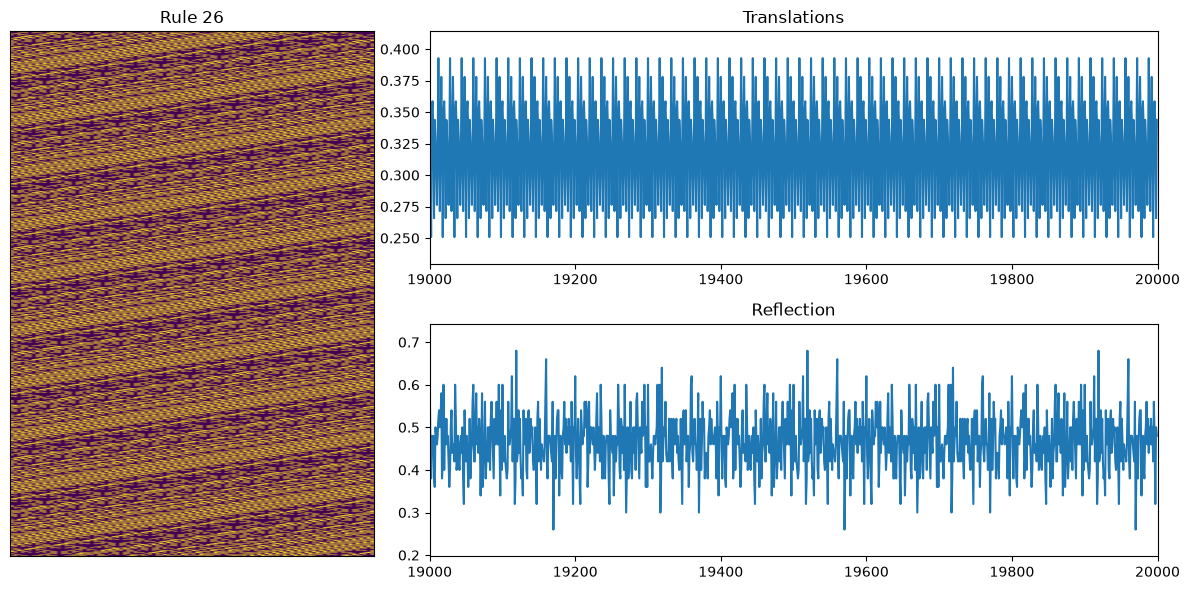

CPU times: total: 55.2 s
Wall time: 1min 2s


In [4]:
%%time

M = 1     # Repetitions
T_cut = 19000
T = 20000      # Time steps
L = 100      # Length of sequence
rule = 26

complexity_r = np.zeros(T)
complexity_t = np.zeros(T)

for _ in range(M):

    # initial_state = np.random.randint(0, 2, L)
    rng = np.random.RandomState(55)
    initial_state = rng.randint(0, 2, L)
    
    complexity_r += CA_complexity(initial_state, T, rule, reflections) 
    complexity_t += CA_complexity(initial_state, T, rule, translations) 

complexity_t /= M    
complexity_r /= M

ctmin = np.min(complexity_t[T_cut:T])
ctmax = np.max(complexity_t[T_cut:T])
trange = ctmax-ctmin
td = 0.15*trange

crmin = np.min(complexity_r[T_cut:T])
crmax = np.max(complexity_r[T_cut:T])
rrange = crmax-crmin
rd = 0.15*rrange
    
fig = plt.figure(figsize=(12, 6))

gs = gridspec.GridSpec(2, 2, width_ratios=[1, 2])

ax1 = fig.add_subplot(gs[:, 0])
ax1.imshow(CA_run(initial_state, T, rule), aspect='auto')
ax1.set_title('Rule '+str(rule))
ax1.set_xticks([])
ax1.set_yticks([])
ax1.set_ylim(T, T_cut)

ax2 = fig.add_subplot(gs[0, 1])
ax2.set_title('Translations')
ax2.set_ylim()
ax2.set_ylim([ctmin-td, ctmax+td])
ax2.plot(complexity_t)
ax2.set_xlim(T_cut, T)

ax3 = fig.add_subplot(gs[1, 1])
ax3.set_title('Reflection')
ax3.set_ylim([crmin-rd, crmax+rd])
ax3.plot(complexity_r)
ax3.set_xlim(T_cut, T)

plt.tight_layout()
plt.show()